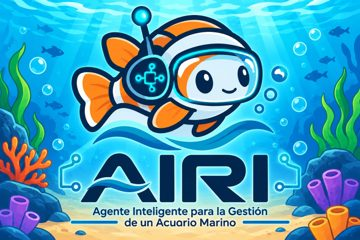

# Grafo de decisiones del agente AIRI — simulación interactiva

**AIRI** — Agente Inteligente para la Supervisión y Gestión de un Acuario Marino.
Actividad de *Fundamentos de la IA* · repositorio oficial [Antoniii28/Airi](https://github.com/Antoniii28/Airi).

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Antoniii28/Airi/blob/feature/grafo-interactivo-airi/grafo/AIRI_Grafo_Interactivo.ipynb)

Este cuaderno construye **desde cero** un grafo dirigido que representa cómo AIRI v0.1 analizaría los
parámetros del agua, y permite **simular** su recorrido con distintos escenarios:

1. Recibe mediciones de **temperatura, pH, salinidad, amoníaco, nitritos y nitratos**.
2. Valida cada dato (presencia, formato, unidad y plausibilidad).
3. Consulta si existe una referencia y evalúa el parámetro.
4. Consolida los resultados, genera alertas y recomendaciones **informativas**.
5. Termina siempre en la **decisión del usuario**: AIRI no ejecuta acciones físicas.

**Cómo usarlo:** menú *Entorno de ejecución → Ejecutar todo*. La interfaz aparece al final del cuaderno.
No requiere instalar nada ni modificar rutas de archivos.

> ⚠ **Importante.** Es una **propuesta de funcionamiento**, no el agente implementado. Los valores de las
> mediciones, los límites de captura y las referencias son **simulados**: no tienen fuente biológica y
> **no deben usarse como recomendaciones para acuarios reales**.

## 1. Configuración

Colores de la **paleta V2** de AIRI (`identidad-visual/README.md`) y los seis parámetros documentados en
`documentacion/01_descripcion_agente.md`. Cada parámetro tiene:

- **unidad esperada** (incluye la especie química cuando corresponde, como pide la descripción del agente);
- **límites de captura simulados**: sirven para detectar errores de captura, **no son rangos biológicos**;
- **referencia simulada**: rango de demostración para recorrer el grafo, **sin fuente biológica**.

In [ ]:
# ═══ 1. Configuración: paleta V2 y parámetros del agua ═══════════════════════
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon, FancyArrowPatch, Rectangle, Patch
from matplotlib.lines import Line2D

# Paleta V2 de AIRI (identidad-visual/README.md del repositorio Antoniii28/Airi)
PALETA = {
    "azul_profundo": "#09284D", "azul_oceano": "#0982C7", "cian": "#39DDF8",
    "aqua": "#80EAF2", "naranja": "#E97A25", "arena": "#F1D495",
    "verde": "#1CAB55", "violeta": "#7B4DD4",
}

# Seis parámetros documentados en documentacion/01_descripcion_agente.md.
# ⚠ LÍMITES DE CAPTURA y REFERENCIAS son SIMULADOS: no tienen fuente biológica,
#   solo sirven para demostrar el recorrido del grafo. No son recomendaciones
#   para acuarios reales.
PARAMETROS = {
    "temperatura": {"nombre": "Temperatura", "unidad": "°C",
                    "otras_unidades": ["°F"],
                    "captura": (0, 40), "referencia": (24, 27)},
    "ph":          {"nombre": "pH", "unidad": "unidades de pH",
                    "otras_unidades": ["mg/L"],
                    "captura": (4, 10), "referencia": (7.8, 8.4)},
    "salinidad":   {"nombre": "Salinidad", "unidad": "ppt",
                    "otras_unidades": ["densidad relativa"],
                    "captura": (0, 50), "referencia": (33, 36)},
    "amoniaco":    {"nombre": "Amoníaco", "unidad": "mg/L NH₃/NH₄⁺ total",
                    "otras_unidades": ["mg/L sin especie química"],
                    "captura": (0, 10), "referencia": (0, 0.25)},
    "nitritos":    {"nombre": "Nitritos", "unidad": "mg/L NO₂⁻",
                    "otras_unidades": ["mg/L sin especie química"],
                    "captura": (0, 10), "referencia": (0, 0.2)},
    "nitratos":    {"nombre": "Nitratos", "unidad": "mg/L NO₃⁻",
                    "otras_unidades": ["mg/L sin especie química"],
                    "captura": (0, 200), "referencia": (0, 25)},
}
ORDEN = list(PARAMETROS)
print("Parámetros:", ", ".join(PARAMETROS[k]["nombre"] for k in ORDEN))
print("⚠ Límites de captura y referencias: SIMULADOS, sin validez biológica.")

## 2. Nodos y aristas

| Grupo | Nodos | Significado |
|---|---|---|
| Entrada | **E0** (estado inicial) | Recibe mediciones manuales o simuladas (F-01, F-11) |
| Validación | **Q1–Q4** | ¿Presente? ¿Número válido? ¿Unidad reconocida? ¿Valor plausible? (F-02, S-07) |
| Evaluación | **Q5–Q6** | ¿Existe referencia con fuente? ¿Dentro de la referencia? (F-03) |
| Estado del parámetro | **EP1–EP5** | Faltante · Inválido · Sin referencia · En rango · Anomalía |
| Consolidación | **C1, Q7** | Calcula **A** (alguna anomalía) e **I** (algún dato no evaluable) y clasifica |
| Resultados | **R1–R4** | En rango · Alertas · Información insuficiente · Alertas + información insuficiente |
| Salidas | **O1, O2** | Recomendación informativa (F-10) · Solicitud de datos (F-06) |
| Estado final | **FIN** | Decisión del usuario; sin acciones físicas (F-10) |

Las decisiones se nombran con **Q** para no confundirlas con el valor lógico **V** (Verdadero).
Cada arista es una transición con su condición (**V**/**F**, o la combinación de A e I).

In [ ]:
# ═══ 2. Definición del grafo: 21 nodos y 30 aristas dirigidas ═══════════════
# categoria: entrada · validacion · evaluacion · no_evaluable · en_rango ·
#            anomalia · consolidacion · resultado_mixto · salida · fin
# propuesta=True → decisión de diseño propuesta (borde discontinuo);
# propuesta=False → requisito documentado (F-xx, S-xx, Txx).
NODOS = {
  "E0":  dict(cat="entrada", forma="caja", pos=(1.95, 9.05), tam=(3.5, 0.95), propuesta=False,
              texto="E0 · Estado inicial\nRecibir mediciones manuales o simuladas", ref="F-01 · F-11 · T07"),
  "Q1":  dict(cat="validacion", forma="rombo", pos=(1.95, 7.3), propuesta=False,
              texto="Q1\n¿Dato presente?", ref="F-02 · F-06"),
  "Q2":  dict(cat="validacion", forma="rombo", pos=(4.5, 7.3), propuesta=False,
              texto="Q2\n¿Número válido?", ref="F-02 · S-07"),
  "Q3":  dict(cat="validacion", forma="rombo", pos=(7.05, 7.3), propuesta=False,
              texto="Q3\n¿Unidad reconocida?", ref="F-02"),
  "Q4":  dict(cat="validacion", forma="rombo", pos=(9.6, 7.3), propuesta=False,
              texto="Q4\n¿Valor plausible?", ref="F-02 · S-07"),
  "Q5":  dict(cat="evaluacion", forma="rombo", pos=(12.15, 7.3), propuesta=False,
              texto="Q5\n¿Referencia\ncon fuente?", ref="F-03 · T06"),
  "Q6":  dict(cat="evaluacion", forma="rombo", pos=(14.7, 7.3), propuesta=False,
              texto="Q6\n¿Dentro de la\nreferencia?", ref="F-03"),
  "EP1": dict(cat="no_evaluable", forma="caja", pos=(1.95, 5.15), tam=(1.95, 0.8), propuesta=False,
              texto="EP1 · FALTANTE", ref="F-06 · T01"),
  "EP2": dict(cat="no_evaluable", forma="caja", pos=(7.05, 5.15), tam=(1.95, 0.8), propuesta=False,
              texto="EP2 · INVÁLIDO", ref="F-02 · T02"),
  "EP3": dict(cat="no_evaluable", forma="caja", pos=(10.9, 5.15), tam=(2.3, 0.8), propuesta=False,
              texto="EP3 · SIN REFERENCIA", ref="F-03 · T06"),
  "EP4": dict(cat="en_rango", forma="caja", pos=(13.3, 5.15), tam=(1.95, 0.8), propuesta=False,
              texto="EP4 · EN RANGO", ref="F-03 · T03"),
  "EP5": dict(cat="anomalia", forma="caja", pos=(15.6, 5.15), tam=(1.95, 0.8), propuesta=False,
              texto="EP5 · ANOMALÍA", ref="F-03 · T04"),
  "C1":  dict(cat="consolidacion", forma="caja", pos=(8.3, 3.55), tam=(4.7, 0.95), propuesta=True,
              texto="C1 · Consolidar los seis resultados\nA = V: alguna ANOMALÍA · I = V: alguno no evaluable",
              ref="Propuesta de diseño · F-04"),
  "Q7":  dict(cat="consolidacion", forma="rombo", pos=(8.3, 2.0), tam=(2.7, 1.05), propuesta=True,
              texto="Q7\nClasificar según A e I", ref="Propuesta de diseño"),
  "R1":  dict(cat="en_rango", forma="caja", pos=(2.3, 0.3), tam=(3.4, 0.95), propuesta=False,
              texto="R1 · INFORME EN RANGO\nno garantiza la salud del acuario", ref="T03 · F-11"),
  "R2":  dict(cat="anomalia", forma="caja", pos=(6.2, 0.3), tam=(3.2, 0.95), propuesta=False,
              texto="R2 · ALERTAS\nuna por parámetro anómalo", ref="F-04 · T04 · T05"),
  "R4":  dict(cat="resultado_mixto", forma="caja", pos=(10.4, 0.3), tam=(3.6, 0.95), propuesta=True,
              texto="R4 · ALERTAS + INFORMACIÓN\nINSUFICIENTE", ref="Propuesta de diseño · F-04 · F-06"),
  "R3":  dict(cat="no_evaluable", forma="caja", pos=(14.55, 0.3), tam=(3.6, 0.95), propuesta=False,
              texto="R3 · INFORMACIÓN INSUFICIENTE\nno declara normalidad", ref="F-04 · F-06 · T01"),
  "O1":  dict(cat="salida", forma="caja", pos=(7.0, -1.25), tam=(3.6, 0.9), propuesta=False,
              texto="O1 · RECOMENDACIÓN INFORMATIVA\nno ejecuta acciones", ref="F-04 · F-10"),
  "O2":  dict(cat="salida", forma="caja", pos=(12.6, -1.25), tam=(3.6, 0.9), propuesta=False,
              texto="O2 · SOLICITUD DE DATOS\nO CORRECCIÓN", ref="F-06"),
  "FIN": dict(cat="fin", forma="caja", pos=(9.8, -2.75), tam=(4.1, 0.9), propuesta=False,
              texto="FIN · Estado final: decisión del usuario\nAIRI no ejecuta acciones físicas", ref="F-10 · T08"),
}

# (origen, destino, etiqueta, estilo de conexión)
ARISTAS = [
  ("E0", "Q1", "para cada parámetro", "arc3"),
  ("Q1", "EP1", "F", "arc3"), ("Q1", "Q2", "V", "arc3"),
  ("Q2", "EP2", "F", "arc3"), ("Q2", "Q3", "V", "arc3"),
  ("Q3", "EP2", "F", "arc3"), ("Q3", "Q4", "V", "arc3"),
  ("Q4", "EP2", "F", "arc3"), ("Q4", "Q5", "V", "arc3"),
  ("Q5", "EP3", "F", "arc3"), ("Q5", "Q6", "V", "arc3"),
  ("Q6", "EP4", "V", "arc3"), ("Q6", "EP5", "F", "arc3"),
  ("EP1", "C1", "registrar", "angle,angleA=-90,angleB=180,rad=0"),
  ("EP2", "C1", "registrar", "arc3"),
  ("EP3", "C1", "registrar", "arc3"),
  ("EP4", "C1", "registrar", "arc3"),
  ("EP5", "C1", "registrar", "angle,angleA=-90,angleB=0,rad=0"),
  ("C1", "Q7", "A, I", "arc3"),
  ("Q7", "R1", "A = F, I = F", "arc3"), ("Q7", "R2", "A = V, I = F", "arc3"),
  ("Q7", "R3", "A = F, I = V", "arc3"), ("Q7", "R4", "A = V, I = V", "arc3"),
  ("R2", "O1", "explicar", "arc3"), ("R4", "O1", "explicar", "arc3"),
  ("R4", "O2", "pedir datos", "arc3"), ("R3", "O2", "pedir datos", "arc3"),
  ("R1", "FIN", "entregar", "angle,angleA=-90,angleB=180,rad=0"),
  ("O1", "FIN", "entregar", "arc3"), ("O2", "FIN", "entregar", "arc3"),
]
SALIDAS = {}
for a, b, etiqueta, _ in ARISTAS:
    SALIDAS.setdefault(a, {})[etiqueta] = b

def siguiente(nodo, etiqueta):
    """Destino de la arista que sale de `nodo` con la condición `etiqueta`."""
    return SALIDAS[nodo][etiqueta]

def verificar_estructura():
    """Comprueba la coherencia del grafo; lanza AssertionError si algo falla."""
    assert len(NODOS) == 21, len(NODOS)
    assert len(ARISTAS) == 30, len(ARISTAS)
    pares = [(a, b) for a, b, _, _ in ARISTAS]
    assert len(pares) == len(set(pares)), "aristas duplicadas"
    for q in ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"]:
        assert sorted(SALIDAS[q]) == ["F", "V"], q
    assert sorted(SALIDAS["Q7"]) == sorted(f"A = {a}, I = {i}" for a in "VF" for i in "VF")
    # acíclico, todo alcanzable desde E0, FIN único terminal
    estado = {}
    def dfs(n):
        estado[n] = 1
        for m in SALIDAS.get(n, {}).values():
            assert estado.get(m) != 1, f"ciclo {n}->{m}"
            if m not in estado:
                dfs(m)
        estado[n] = 2
    dfs("E0")
    assert set(estado) == set(NODOS), set(NODOS) - set(estado)
    assert [n for n in NODOS if n not in SALIDAS] == ["FIN"]
    return True

verificar_estructura()
print(f"Grafo coherente: {len(NODOS)} nodos, {len(ARISTAS)} aristas, acíclico, "
      "todas las decisiones con salidas V/F y un único estado final (FIN).")

## 3. Lógica del agente

Cada parámetro recorre **Q1 → Q6** y termina en un estado **EP**. Después se consolidan los seis estados:

- **A = V** si algún parámetro está en ANOMALÍA.
- **I = V** si algún parámetro está FALTANTE, INVÁLIDO o SIN REFERENCIA.

| A | I | Resultado |
|---|---|---|
| F | F | **R1** · informe en rango (no garantiza la salud del acuario) |
| V | F | **R2** · alertas |
| F | V | **R3** · información insuficiente (no declara normalidad) |
| V | V | **R4** · alertas + información insuficiente (no oculta las anomalías válidas) |

La evaluación por parámetro y la clasificación por A e I son **propuestas de diseño** del equipo
(`docs/ORGANIZACION_Y_FLUJO_TRABAJO.md`); amplían la lógica de `docs/CRITERIOS_V0.1.md`.
Lo desconocido **no se convierte en F**: un dato faltante o sin referencia queda como *no evaluado*.

En esta simulación, la "referencia con fuente" de Q5 es la tabla de referencias **simuladas**. En AIRI real,
solo contarían referencias documentadas con fuente técnica verificable.

In [ ]:
# ═══ 3. Lógica del agente: recorrer el grafo con unas mediciones ═════════════
ESTADO_NOMBRE = {"EP1": "FALTANTE", "EP2": "INVÁLIDO", "EP3": "SIN REFERENCIA",
                 "EP4": "EN RANGO", "EP5": "ANOMALÍA"}

def _numero(texto):
    """Convierte el texto a número finito (acepta coma decimal) o devuelve None."""
    try:
        valor = float(str(texto).strip().replace(",", "."))
    except ValueError:
        return None
    return valor if math.isfinite(valor) else None

def evaluar_parametro(clave, texto, unidad, referencia_disponible=True):
    """Recorre Q1…Q6 para un parámetro. Devuelve estado, aristas recorridas y motivo."""
    p = PARAMETROS[clave]
    aristas, nodo = [], "Q1"
    def paso(condicion, etiqueta_ok="V"):
        nonlocal nodo
        etiqueta = etiqueta_ok if condicion else "F"
        destino = siguiente(nodo, etiqueta)
        aristas.append((nodo, destino, etiqueta))
        nodo = destino
        return condicion

    valor = None
    if not paso(texto is not None and str(texto).strip() != ""):
        motivo = "no se recibió el dato"
    elif not paso((valor := _numero(texto)) is not None):
        motivo = f"«{texto}» no es un número válido"
    elif not paso(unidad == p["unidad"]):
        motivo = f"unidad «{unidad}» no reconocida (se espera {p['unidad']})"
    elif not paso(p["captura"][0] <= valor <= p["captura"][1]):
        motivo = (f"{valor:g} está fuera de los límites de captura simulados "
                  f"[{p['captura'][0]:g}, {p['captura'][1]:g}]")
    elif not paso(referencia_disponible):
        motivo = "no hay referencia con fuente para este parámetro: no se evalúa"
    else:
        bajo, alto = p["referencia"]
        dentro = paso(bajo <= valor <= alto)
        if dentro:
            motivo = f"{valor:g} dentro de la referencia simulada [{bajo:g}, {alto:g}]"
        else:
            lado = "por encima" if valor > alto else "por debajo"
            motivo = f"{valor:g} {lado} de la referencia simulada [{bajo:g}, {alto:g}]"
    return {"clave": clave, "estado": nodo, "aristas": aristas, "valor": valor,
            "texto": texto, "unidad": unidad, "motivo": motivo}

def simular(mediciones):
    """
    mediciones: {clave: {"valor": texto, "unidad": str, "referencia": bool}}
    Devuelve el informe completo y la traza paso a paso del recorrido.
    """
    traza = []   # (origen, destino, etiqueta, parámetro o None, mensaje)
    resultados = []
    for clave in ORDEN:
        m = mediciones.get(clave, {})
        r = evaluar_parametro(clave, m.get("valor"), m.get("unidad", PARAMETROS[clave]["unidad"]),
                              m.get("referencia", True))
        resultados.append(r)
        nombre = PARAMETROS[clave]["nombre"]
        traza.append(("E0", "Q1", "para cada parámetro", clave, f"{nombre}: inicia la validación"))
        for a, b, etiqueta in r["aristas"]:
            traza.append((a, b, etiqueta, clave, f"{nombre}: {a} → {etiqueta} → {b}"))
        traza.append((r["estado"], "C1", "registrar", clave,
                      f"{nombre}: {ESTADO_NOMBRE[r['estado']]} ({r['motivo']})"))

    A = any(r["estado"] == "EP5" for r in resultados)
    I = any(r["estado"] in ("EP1", "EP2", "EP3") for r in resultados)
    vf = lambda x: "V" if x else "F"
    traza.append(("C1", "Q7", "A, I", None, f"Consolidación: A = {vf(A)}, I = {vf(I)}"))
    etiqueta = f"A = {vf(A)}, I = {vf(I)}"
    resultado = siguiente("Q7", etiqueta)
    traza.append(("Q7", resultado, etiqueta, None, f"Clasificación: {etiqueta} → {resultado}"))
    pendientes = [resultado]
    while pendientes:                       # recorre las salidas hasta FIN
        n = pendientes.pop(0)
        for etq, destino in SALIDAS.get(n, {}).items():
            if (n, destino) not in [(t[0], t[1]) for t in traza]:
                traza.append((n, destino, etq, None, f"{n} → {etq} → {destino}"))
                pendientes.append(destino)

    alertas = [r for r in resultados if r["estado"] == "EP5"]
    no_evaluados = [r for r in resultados if r["estado"] in ("EP1", "EP2", "EP3")]
    return {"resultados": resultados, "A": A, "I": I, "resultado": resultado,
            "alertas": alertas, "no_evaluados": no_evaluados, "traza": traza}

def recomendacion(r):
    """Texto informativo y prudente; nunca una acción automática."""
    n = PARAMETROS[r["clave"]]["nombre"]
    return (f"{n}: repetir la medición para confirmarla y revisar, con una persona con "
            f"experiencia, la referencia aplicable al perfil del acuario antes de decidir "
            f"cualquier intervención.")

def solicitud(r):
    n = PARAMETROS[r["clave"]]["nombre"]
    if r["estado"] == "EP1":
        return f"{n}: proporcionar la medición."
    if r["estado"] == "EP2":
        return f"{n}: corregir el dato ({r['motivo']})."
    return f"{n}: documentar una referencia con fuente para este perfil."

print("Lógica cargada: evaluar_parametro() y simular().")

## 4. Escenarios de prueba

Seis escenarios mínimos solicitados más uno adicional (*referencia no disponible*). Todos usan valores **simulados**.

In [ ]:
# ═══ 4. Escenarios de demostración (valores SIMULADOS) ════════════════════════
def _base(**cambios):
    """Mediciones simuladas dentro de las referencias simuladas, con cambios."""
    valores = {"temperatura": "25.5", "ph": "8.1", "salinidad": "35",
               "amoniaco": "0.05", "nitritos": "0.05", "nitratos": "10"}
    m = {k: {"valor": v, "unidad": PARAMETROS[k]["unidad"], "referencia": True}
         for k, v in valores.items()}
    for clave, cambio in cambios.items():
        m[clave].update(cambio)
    return m

# nombre: (mediciones, resultado esperado, descripción)
ESCENARIOS = {
  "1 · Parámetros dentro de las referencias simuladas":
      (_base(), "R1", "Los seis valores son válidos y están dentro de las referencias simuladas."),
  "2 · Una anomalía":
      (_base(amoniaco={"valor": "0.8"}), "R2", "El amoníaco simulado supera su referencia."),
  "3 · Varias anomalías":
      (_base(temperatura={"valor": "29"}, ph={"valor": "7.5"}, nitritos={"valor": "0.6"}),
       "R2", "Temperatura, pH y nitritos simulados fuera de referencia."),
  "4 · Información incompleta":
      (_base(ph={"valor": ""}, nitratos={"valor": ""}), "R3", "Faltan el pH y los nitratos."),
  "5 · Datos inválidos":
      (_base(salinidad={"valor": "treinta y cinco"},
             temperatura={"valor": "77", "unidad": "°F"},
             nitratos={"valor": "-4"}),
       "R3", "Texto en lugar de número, unidad no reconocida y valor no plausible."),
  "6 · Anomalías + información insuficiente":
      (_base(amoniaco={"valor": "0.8"}, nitratos={"valor": "45"},
             ph={"valor": ""}, salinidad={"valor": "3x5"}),
       "R4", "Dos anomalías válidas, un dato faltante y uno inválido."),
  "7 · Referencia no disponible":
      (_base(nitratos={"referencia": False}), "R3",
       "No hay referencia con fuente para los nitratos: no se evalúan."),
}
for nombre, (med, esperado, _) in ESCENARIOS.items():
    print(f"{nombre:<52} → resultado esperado {esperado}")

## 5. Visualización del grafo

Grafo completo antes de simular. Durante la simulación, el recorrido se resalta en **azul profundo** (el número
`×n` indica cuántos parámetros pasaron por esa transición), el **paso actual** en **naranja**, y los nodos no
visitados se atenúan. Borde discontinuo = propuesta de diseño.

In [ ]:
# ═══ 5. Visualización del grafo y resaltado del recorrido ═════════════════════
from collections import Counter

COLOR_CAT = {
    "entrada": PALETA["azul_profundo"], "fin": PALETA["azul_profundo"],
    "validacion": PALETA["azul_oceano"], "evaluacion": PALETA["cian"],
    "no_evaluable": PALETA["arena"], "en_rango": PALETA["verde"],
    "anomalia": PALETA["naranja"], "consolidacion": PALETA["violeta"],
    "resultado_mixto": PALETA["naranja"], "salida": PALETA["aqua"],
}
TEXTO_CLARO = {"entrada", "fin", "validacion", "consolidacion"}
ABREV = {"temperatura": "Temp.", "ph": "pH", "salinidad": "Sal.",
         "amoniaco": "Amon.", "nitritos": "Nitritos", "nitratos": "Nitratos"}
ROMBO = (1.95, 1.25)
GRIS = "#A9BACB"

# Posición de etiquetas que no van en el punto medio de la arista
POS_ETIQUETA = {("EP1", "C1"): (1.95, 4.15), ("EP5", "C1"): (15.6, 4.15),
                ("R1", "FIN"): (2.3, -1.55), ("E0", "Q1"): (3.05, 8.25)}

def _tam(nid):
    n = NODOS[nid]
    return n.get("tam", ROMBO) if n["forma"] == "rombo" else n["tam"]

def _borde(nid, dx, dy):
    """Punto del contorno del nodo en la dirección (dx, dy) desde su centro."""
    (x, y), (w, h) = NODOS[nid]["pos"], _tam(nid)
    if NODOS[nid]["forma"] == "rombo":
        t = 1 / (abs(dx) / (w / 2) + abs(dy) / (h / 2))
    else:
        t = min((w / 2) / abs(dx) if dx else math.inf, (h / 2) / abs(dy) if dy else math.inf)
    return (x + t * dx, y + t * dy)

def _extremos(a, b, conexion):
    """Extremos de cada flecha sobre el contorno de los nodos. La geometría no
    cambia entre cuadros, así que se calcula una sola vez (animación más fluida)."""
    (xa, ya), (xb, yb) = NODOS[a]["pos"], NODOS[b]["pos"]
    if conexion.startswith("angle"):          # baja desde A y entra de lado en B
        lado = -1 if xa < xb else 1
        return (xa, ya - _tam(a)[1] / 2), (xb + lado * _tam(b)[0] / 2, yb)
    return _borde(a, xb - xa, yb - ya), _borde(b, xa - xb, ya - yb)

EXTREMOS = {(a, b): _extremos(a, b, c) for a, b, _, c in ARISTAS}

def _pasos(informe, hasta, foco):
    if not informe:
        return []
    pasos = informe["traza"][:hasta] if hasta is not None else informe["traza"]
    if foco:
        pasos = [p for p in pasos if p[3] in (foco, None)]
    return pasos

def dibujar(informe=None, hasta=None, foco=None, escenario=""):
    """Dibuja el grafo. Con `informe`, resalta el recorrido hasta el paso `hasta`."""
    pasos = _pasos(informe, hasta, foco)
    activo = informe is not None
    conteo = Counter((a, b) for a, b, *_ in pasos)
    visitados = {n for a, b, *_ in pasos for n in (a, b)}
    actual = pasos[-1] if (activo and hasta is not None and pasos) else None
    inicial = activo and hasta is not None and not pasos      # paso 0: estado inicial
    if inicial:
        visitados = {"E0"}
    por_estado = {}
    for a, b, _, clave, _ in pasos:
        if b == "C1" and clave:
            por_estado.setdefault(a, []).append(ABREV[clave])

    fig, ax = plt.subplots(figsize=(16, 12.4))
    fig.patch.set_facecolor("white")
    ax.set_xlim(0.1, 16.85); ax.set_ylim(-3.5, 11.15); ax.axis("off")

    # Título y estado de la simulación
    ax.text(8.45, 10.75, "Grafo de decisiones del agente AIRI", ha="center", va="center",
            fontsize=19, weight="bold", color=PALETA["azul_profundo"])
    ax.text(8.45, 10.3, "Simulación de la propuesta de funcionamiento de AIRI v0.1 · "
            "valores y referencias SIMULADOS, sin validez biológica",
            ha="center", va="center", fontsize=10.5, color=PALETA["azul_profundo"])
    if activo:
        estado = f"Escenario: {escenario}" if escenario else "Escenario personalizado"
        if actual:
            estado += f"   ·   Paso {len(pasos)} de {len(_pasos(informe, None, foco))}: {actual[4]}"
        elif inicial:
            estado += "   ·   Paso 0: estado inicial E0 (mediciones recibidas)"
        else:
            estado += f"   ·   Resultado: {informe['resultado']}"
        if foco:
            estado += f"   ·   Recorrido de: {PARAMETROS[foco]['nombre']}"
        ax.text(8.45, 9.88, estado, ha="center", va="center", fontsize=9.5,
                color=PALETA["azul_profundo"], style="italic")

    # Recuadro del bloque que se repite por parámetro (propuesta de diseño)
    ax.add_patch(FancyBboxPatch((0.55, 4.45), 16.15, 3.9, boxstyle="round,pad=0,rounding_size=0.15",
                 facecolor="#F4FCFD", edgecolor=PALETA["azul_oceano"], linestyle="--", lw=1.4, zorder=0))
    ax.text(16.55, 8.12, "Evaluación individual — se repite para cada uno de los seis parámetros "
            "(propuesta de diseño)", fontsize=9.5, color=PALETA["azul_profundo"], va="center", ha="right")

    # Nodos
    parches = {}
    for nid, n in NODOS.items():
        x, y = n["pos"]
        color = COLOR_CAT[n["cat"]]
        apagado = activo and nid not in visitados
        borde = PALETA["azul_profundo"]
        lw = 2.6 if (activo and not apagado) else 1.4
        if (actual and nid == actual[1]) or (inicial and nid == "E0"):
            borde, lw = PALETA["naranja"], 4.0
        estilo = "--" if n["propuesta"] else "-"
        if n["forma"] == "rombo":
            w, h = n.get("tam", ROMBO)
            p = Polygon([(x, y + h/2), (x + w/2, y), (x, y - h/2), (x - w/2, y)], closed=True,
                        facecolor=color, edgecolor=borde, lw=lw, linestyle=estilo, zorder=3)
        else:
            w, h = n["tam"]
            p = FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0,rounding_size=0.12",
                               facecolor=color, edgecolor=borde, lw=lw, linestyle=estilo, zorder=3)
        if n["cat"] == "resultado_mixto":       # mitad naranja / mitad arena
            p.set_facecolor(PALETA["naranja"])
            ax.add_patch(FancyBboxPatch((x, y - h/2), w/2, h, boxstyle="round,pad=0,rounding_size=0.12",
                         facecolor=PALETA["arena"], edgecolor="none", zorder=3.1,
                         alpha=0.3 if apagado else 1))
        if apagado:
            p.set_alpha(0.3)
        ax.add_patch(p)
        parches[nid] = p
        color_texto = "white" if n["cat"] in TEXTO_CLARO else PALETA["azul_profundo"]
        alfa = 0.45 if apagado else 1
        lineas = n["texto"].split("\n")
        extra = n["ref"]
        if nid in por_estado:
            nombres = por_estado[nid]
            extra = "\n".join(", ".join(nombres[i:i+3]) for i in range(0, len(nombres), 3))
        cuerpo = "\n".join(lineas[1:])
        tam = 8.6
        ax.text(x, y + (0.13 if cuerpo or extra else 0) + (0.06 if cuerpo and extra else 0),
                lineas[0], ha="center", va="center", fontsize=tam, weight="bold",
                color=color_texto, alpha=alfa, zorder=4)
        abajo = "\n".join(t for t in [cuerpo] if t)
        if abajo:
            ax.text(x, y - 0.05, abajo, ha="center", va="center", fontsize=7.8,
                    color=color_texto, alpha=alfa, zorder=4, linespacing=1.15)
        if extra:
            ax.text(x, y - (0.3 if abajo else 0.17), extra, ha="center", va="center",
                    fontsize=6.9 if nid not in por_estado else 7.4,
                    weight="normal" if nid not in por_estado else "bold",
                    color=color_texto, alpha=alfa, zorder=4, linespacing=1.1)

    # Aristas
    for a, b, etiqueta, conexion in ARISTAS:
        veces = conteo.get((a, b), 0)
        es_actual = actual is not None and (actual[0], actual[1]) == (a, b)
        if es_actual:
            color, lw = PALETA["naranja"], 4.2
        elif veces:
            color, lw = PALETA["azul_profundo"], 3.2
        else:
            color, lw = (GRIS, 1.2) if activo else (PALETA["azul_profundo"], 1.3)
        inicio, fin = EXTREMOS[(a, b)]
        flecha = FancyArrowPatch(inicio, fin, connectionstyle=conexion, arrowstyle="-|>",
                                 mutation_scale=15, color=color, lw=lw, shrinkA=0, shrinkB=1, zorder=2)
        ax.add_artist(flecha)
        (xa, ya), (xb, yb) = NODOS[a]["pos"], NODOS[b]["pos"]
        lx, ly = POS_ETIQUETA.get((a, b), ((xa + xb) / 2, (ya + yb) / 2))
        texto = etiqueta + (f"  ×{veces}" if veces > 1 else "")
        ax.text(lx, ly, texto, ha="center", va="center", fontsize=8.6 if len(etiqueta) <= 2 else 7.8,
                weight="bold", color=color if (veces or es_actual) else
                (PALETA["azul_profundo"] if not activo else "#6B7F93"),
                bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.92), zorder=5)

    # Leyenda
    elementos = [Patch(fc=PALETA["azul_profundo"], label="Entrada / estado final"),
                 Patch(fc=PALETA["azul_oceano"], label="Validación"),
                 Patch(fc=PALETA["cian"], label="Evaluación"),
                 Patch(fc=PALETA["verde"], label="En rango"),
                 Patch(fc=PALETA["naranja"], label="Anomalía / alerta"),
                 Patch(fc=PALETA["arena"], label="No evaluable / insuficiente"),
                 Patch(fc=PALETA["violeta"], label="Consolidación"),
                 Patch(fc=PALETA["aqua"], label="Salida informativa"),
                 Patch(fc="white", ec=PALETA["azul_profundo"], ls="--", label="Propuesta de diseño"),
                 Line2D([0], [0], color=PALETA["azul_profundo"], lw=3.2, label="Recorrido (×n = parámetros)"),
                 Line2D([0], [0], color=PALETA["naranja"], lw=4, label="Paso actual")]
    ax.legend(handles=elementos, loc="lower right", ncol=2, fontsize=7.6, frameon=True,
              framealpha=1, edgecolor=PALETA["azul_profundo"], bbox_to_anchor=(1.0, 0.0),
              title="Rombo = decisión · Caja = estado · V = Verdadero · F = Falso",
              title_fontsize=7.6)
    fig.subplots_adjust(left=0.005, right=0.995, top=0.995, bottom=0.005)   # tamaño fijo
    return fig

_fig = dibujar()
plt.show()

## 6. Verificación automática

Comprueba la estructura del grafo, los siete escenarios y **todas** las combinaciones posibles de estados
para los seis parámetros (7⁶ = 117 649). Si algo fallara, la celda mostraría un error.

In [ ]:
# ═══ 6. Verificación automática de la lógica ═════════════════════════════════
import itertools, time

verificar_estructura()
print("✔ Estructura: 21 nodos, 30 aristas, acíclico, decisiones V/F completas, FIN único.\n")

print(f"{'Escenario':<52}{'Esperado':>9}{'Obtenido':>10}  Alertas  No evaluados")
for nombre, (med, esperado, _) in ESCENARIOS.items():
    inf = simular(med)
    assert inf["resultado"] == esperado, (nombre, inf["resultado"])
    assert inf["traza"][-1][1] == "FIN"
    print(f"{nombre:<52}{esperado:>9}{inf['resultado']:>10}  {len(inf['alertas']):>7}  {len(inf['no_evaluados']):>12}")
print("✔ Los siete escenarios llegan al resultado esperado y terminan en FIN.\n")

# Prueba exhaustiva: cada parámetro en cada uno de 7 casos posibles (7⁶ combinaciones)
def _caso(clave, tipo):
    p = PARAMETROS[clave]; bajo, alto = p["referencia"]; cmax = p["captura"][1]
    valor = {"en_rango": (bajo + alto) / 2, "anomalia": (alto + cmax) / 2,
             "faltante": "", "formato": "abc", "unidad": (bajo + alto) / 2,
             "implausible": cmax + 1, "sin_ref": (bajo + alto) / 2}[tipo]
    unidad = p["otras_unidades"][0] if tipo == "unidad" else p["unidad"]
    return {"valor": str(valor), "unidad": unidad, "referencia": tipo != "sin_ref"}

TIPOS = ["en_rango", "anomalia", "faltante", "formato", "unidad", "implausible", "sin_ref"]
ESPERADO_EP = {"en_rango": "EP4", "anomalia": "EP5", "faltante": "EP1", "formato": "EP2",
               "unidad": "EP2", "implausible": "EP2", "sin_ref": "EP3"}
inicio, total = time.time(), 0
for combo in itertools.product(TIPOS, repeat=len(ORDEN)):
    inf = simular({k: _caso(k, t) for k, t in zip(ORDEN, combo)})
    estados = [r["estado"] for r in inf["resultados"]]
    assert estados == [ESPERADO_EP[t] for t in combo]
    hay_anomalia, hay_insuficiente = "anomalia" in combo, any(t not in ("en_rango", "anomalia") for t in combo)
    visitados = {b for _, b, *_ in inf["traza"]}
    assert (inf["resultado"] == "R1") == (not hay_anomalia and not hay_insuficiente)   # nunca "en rango" con pendientes
    assert len(inf["alertas"]) == combo.count("anomalia")                            # ninguna alerta se oculta
    assert ("O1" in visitados) == hay_anomalia and ("O2" in visitados) == hay_insuficiente
    assert "FIN" in visitados
    total += 1
print(f"✔ {total:,} combinaciones comprobadas en {time.time() - inicio:.1f} s: nunca se informa "
      "«en rango» con anomalías o datos no evaluados, ninguna alerta se pierde y todo termina en FIN.")

## 7. Simulación interactiva

1. Elige un **escenario** (las mediciones se cargan abajo; puedes editarlas para crear tu propio caso).
2. **▶ Reproducir**: la simulación avanza **sola**, como un video, desde el estado inicial E0 hasta FIN.
   El nodo activo y la conexión recorrida se marcan en **naranja**; lo ya recorrido queda en azul profundo.
   Al terminar se detiene y muestra el informe de AIRI.
3. **⏸ Pausar** detiene la reproducción sin perder el avance; **▶ Continuar** la reanuda desde ese paso.
4. **↺ Reiniciar** detiene la reproducción y vuelve al estado inicial.
5. **Velocidad**: Lenta (1.5 s por paso), Normal (0.8 s, predeterminada) o Rápida (0.3 s).
6. **Siguiente paso** (opcional) avanza manualmente de uno en uno; **Recorrido a resaltar** sigue un solo parámetro.

La reproducción usa una tarea asíncrona del kernel: los botones siguen respondiendo mientras avanza y
nunca hay dos reproducciones a la vez. Si el entorno se reinicia, vuelve a ejecutar todo el cuaderno.

In [ ]:
# ═══ 7. Simulación interactiva con reproducción automática ════════════════════
# La animación usa una tarea asyncio del propio kernel: entre un paso y otro
# espera con `await asyncio.sleep`, así los botones Pausar/Reiniciar siguen
# respondiendo. Cada cuadro se dibuja en un widget de imagen de tamaño fijo y el
# informe en un widget HTML (actualizar el valor de un widget funciona también
# desde una tarea en segundo plano, a diferencia de imprimir en un Output).
import asyncio, html, io, time
import ipywidgets as widgets
from IPython.display import display

estado = {"informe": None, "paso": None, "cargando": False,
          "tarea": None, "generacion": 0, "pausado": False}
ANCHO = {"description_width": "initial"}

sel_escenario = widgets.Dropdown(options=list(ESCENARIOS), description="Escenario:",
                                 style=ANCHO, layout=widgets.Layout(width="470px"))
sel_foco = widgets.Dropdown(options=[("Todos los parámetros", None)] +
                            [(PARAMETROS[k]["nombre"], k) for k in ORDEN],
                            description="Recorrido a resaltar:", style=ANCHO,
                            layout=widgets.Layout(width="330px"))
sel_velocidad = widgets.ToggleButtons(options=[("Lenta", 1.5), ("Normal", 0.8), ("Rápida", 0.3)],
                                      value=0.8, description="Velocidad:", style=ANCHO,
                                      tooltips=["1.5 s por paso", "0.8 s por paso", "0.3 s por paso"])
btn_reproducir = widgets.Button(description="Reproducir", icon="play", button_style="primary",
                                layout=widgets.Layout(width="140px"))
btn_pausar = widgets.Button(description="Pausar", icon="pause", button_style="warning",
                            layout=widgets.Layout(width="120px"))
btn_continuar = widgets.Button(description="Continuar", icon="play", button_style="success",
                               layout=widgets.Layout(width="130px"))
btn_reiniciar = widgets.Button(description="Reiniciar", icon="refresh", layout=widgets.Layout(width="120px"))
btn_paso = widgets.Button(description="Siguiente paso", icon="step-forward",
                          tooltip="Avance manual opcional (pausa la reproducción)",
                          layout=widgets.Layout(width="150px"))
descripcion = widgets.HTML()
imagen_grafo = widgets.Image(format="png", layout=widgets.Layout(width="100%", max_width="1280px"))
panel_resultados = widgets.HTML()

entradas = {}
filas = [widgets.HTML("<b>Mediciones simuladas</b> (puedes editarlas: deja vacío un valor para "
                      "simular un dato faltante o escribe texto para simular un dato inválido)")]
for k in ORDEN:
    p = PARAMETROS[k]
    valor = widgets.Text(continuous_update=False, layout=widgets.Layout(width="150px"))
    unidad = widgets.Dropdown(options=[p["unidad"]] + p["otras_unidades"], layout=widgets.Layout(width="210px"))
    referencia = widgets.Checkbox(value=True, description="referencia disponible", indent=False)
    entradas[k] = (valor, unidad, referencia)
    filas.append(widgets.HBox([widgets.HTML(f"<div style='width:110px'>{p['nombre']}</div>"),
                               valor, unidad, referencia]))
panel_entradas = widgets.VBox(filas, layout=widgets.Layout(border="1px solid #80EAF2",
                                                           padding="6px", margin="6px 0"))

def leer_mediciones():
    return {k: {"valor": v.value, "unidad": u.value, "referencia": r.value}
            for k, (v, u, r) in entradas.items()}

def nombre_escenario():
    med, _, _ = ESCENARIOS[sel_escenario.value]
    return sel_escenario.value if leer_mediciones() == med else "personalizado"

def mostrar_grafo():
    """Dibuja el cuadro actual como PNG de tamaño fijo (sin parpadeo ni saltos)."""
    fig = dibujar(estado["informe"], estado["paso"], sel_foco.value, nombre_escenario())
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=80, facecolor="white", pil_kwargs={"compress_level": 1})
    plt.close(fig)
    imagen_grafo.value = buffer.getvalue()

def _insignia(ep):
    color = {"EP1": PALETA["arena"], "EP2": PALETA["arena"], "EP3": PALETA["arena"],
             "EP4": PALETA["verde"], "EP5": PALETA["naranja"]}[ep]
    return (f"<span style='background:{color};color:{PALETA['azul_profundo']};padding:2px 8px;"
            f"border-radius:10px;font-weight:bold'>{ESTADO_NOMBRE[ep]}</span>")

def reproduciendo():
    return estado["tarea"] is not None and not estado["tarea"].done()

def html_resultados():
    inf = estado["informe"]
    if inf is None:
        return ("<p><i>Selecciona un escenario y pulsa <b>Reproducir</b>. La simulación avanzará "
                "sola hasta el final; puedes pausarla, continuarla o reiniciarla.</i></p>")
    total = len(inf["traza"])
    if estado["paso"] is not None and estado["paso"] < total:
        if estado["paso"] == 0:
            actual = "estado inicial E0: AIRI recibe las mediciones"
        else:
            actual = inf["traza"][estado["paso"] - 1][4]
        modo = ("reproduciendo" if reproduciendo() else
                "en pausa" if estado["pausado"] else "avance manual")
        return (f"<p><b>Paso {estado['paso']} de {total}</b> ({modo}): {html.escape(actual)}</p>"
                f"<progress value='{estado['paso']}' max='{total}' style='width:60%'></progress>"
                "<p><i>El informe de AIRI aparece al completar el recorrido.</i></p>")
    filas = "".join(
        f"<tr><td>{PARAMETROS[r['clave']]['nombre']}</td><td>{html.escape(str(r['texto']))}</td>"
        f"<td>{html.escape(r['unidad'])}</td><td>{_insignia(r['estado'])}</td>"
        f"<td>{html.escape(r['motivo'])}</td></tr>" for r in inf["resultados"])
    vf = lambda x: "V" if x else "F"
    titulo = {"R1": "R1 · Informe en rango", "R2": "R2 · Alertas",
              "R3": "R3 · Información insuficiente",
              "R4": "R4 · Alertas + información insuficiente"}[inf["resultado"]]
    partes = [f"<h3 style='color:{PALETA['azul_profundo']};margin-bottom:4px'>Resultado: {titulo}</h3>",
              f"<p>A (alguna anomalía) = <b>{vf(inf['A'])}</b> · "
              f"I (algún dato no evaluable) = <b>{vf(inf['I'])}</b></p>",
              "<table style='border-collapse:collapse' border='1' cellpadding='4'>"
              "<tr style='background:#09284D;color:white'><th>Parámetro</th><th>Valor</th>"
              f"<th>Unidad</th><th>Estado</th><th>Motivo</th></tr>{filas}</table>"]
    if inf["resultado"] == "R1":
        partes.append("<p>✅ Los seis parámetros están dentro de las referencias <b>simuladas</b>. "
                      "Esto <b>no garantiza</b> la salud del acuario.</p>")
    if inf["alertas"]:
        partes.append("<h4>⚠ Alertas</h4><ul>" + "".join(
            f"<li><b>{PARAMETROS[r['clave']]['nombre']}</b>: {html.escape(r['motivo'])}</li>"
            for r in inf["alertas"]) + "</ul>")
        partes.append("<h4>Recomendaciones informativas</h4><ul>" + "".join(
            f"<li>{html.escape(recomendacion(r))}</li>" for r in inf["alertas"]) + "</ul>")
    if inf["no_evaluados"]:
        partes.append("<h4>Información insuficiente — datos que se solicitan</h4><ul>" + "".join(
            f"<li>{html.escape(solicitud(r))}</li>" for r in inf["no_evaluados"]) + "</ul>"
            "<p>No se declara que el acuario esté en condiciones normales.</p>")
    partes.append("<p style='font-size:90%'><b>Decisión final:</b> una persona revisa el informe y "
                  "decide. AIRI no ejecuta acciones físicas (F-10). Valores y referencias "
                  "<b>simulados</b>, sin validez biológica.</p>")
    return "".join(partes)

def actualizar_botones():
    total = len(estado["informe"]["traza"]) if estado["informe"] else 0
    terminado = estado["informe"] is not None and estado["paso"] is not None and estado["paso"] >= total
    btn_pausar.disabled = not reproduciendo()
    btn_continuar.disabled = reproduciendo() or estado["informe"] is None or terminado
    btn_paso.disabled = terminado

def actualizar():
    mostrar_grafo()
    panel_resultados.value = html_resultados()
    actualizar_botones()

# ── Reproducción automática ────────────────────────────────────────────────
def _detener():
    """Cancela la reproducción en curso; ninguna tarea anterior queda activa."""
    estado["generacion"] += 1
    tarea = estado["tarea"]
    if tarea is not None and not tarea.done():
        tarea.cancel()
    estado["tarea"] = None

async def _reproducir(generacion):
    try:
        total = len(estado["informe"]["traza"])
        espera = sel_velocidad.value
        while estado["paso"] < total:
            await asyncio.sleep(espera)
            if generacion != estado["generacion"]:      # fue pausada o reiniciada
                return
            inicio = time.monotonic()
            estado["paso"] += 1
            actualizar()
            # descuenta el tiempo de dibujo para respetar la velocidad elegida
            espera = max(0.02, sel_velocidad.value - (time.monotonic() - inicio))
    except asyncio.CancelledError:
        pass
    finally:
        if generacion == estado["generacion"]:          # terminó sola: se detiene
            estado["tarea"] = None
            panel_resultados.value = html_resultados()
            actualizar_botones()

def _iniciar_tarea():
    _detener()
    estado["pausado"] = False
    estado["tarea"] = asyncio.ensure_future(_reproducir(estado["generacion"]))
    panel_resultados.value = html_resultados()
    actualizar_botones()

def reproducir(_=None):
    """▶ Reproducir: inicia (o reinicia) la simulación desde el estado inicial."""
    _detener()
    estado["informe"] = simular(leer_mediciones())
    estado["paso"], estado["pausado"] = 0, False
    actualizar()                                         # muestra el estado inicial E0
    _iniciar_tarea()

def pausar(_=None):
    """⏸ Pausar: detiene la reproducción conservando el paso actual."""
    if reproduciendo():
        _detener()
        estado["pausado"] = True
        panel_resultados.value = html_resultados()
        actualizar_botones()

def continuar(_=None):
    """▶ Continuar: reanuda desde el paso en que se pausó."""
    if (estado["informe"] is not None and estado["paso"] is not None
            and estado["paso"] < len(estado["informe"]["traza"]) and not reproduciendo()):
        _iniciar_tarea()

def siguiente_paso(_=None):
    """Avance manual opcional: pausa la reproducción y avanza un paso."""
    _detener()
    if estado["informe"] is None or estado["paso"] is None:
        estado["informe"] = simular(leer_mediciones())
        estado["paso"] = 0
    else:
        estado["paso"] = min(estado["paso"] + 1, len(estado["informe"]["traza"]))
    estado["pausado"] = estado["paso"] < len(estado["informe"]["traza"])
    actualizar()

def reiniciar(_=None):
    """↺ Reiniciar: detiene la reproducción y vuelve al estado sin simular."""
    _detener()
    estado["informe"], estado["paso"], estado["pausado"] = None, None, False
    actualizar()

def cargar_escenario(_=None):
    med, esperado, texto = ESCENARIOS[sel_escenario.value]
    estado["cargando"] = True
    for k, (v, u, r) in entradas.items():
        v.value, u.value, r.value = med[k]["valor"], med[k]["unidad"], med[k]["referencia"]
    descripcion.value = f"<i>{html.escape(texto)}</i>"
    estado["cargando"] = False
    reiniciar()

sel_escenario.observe(cargar_escenario, names="value")
sel_foco.observe(lambda _: mostrar_grafo(), names="value")
for _w in [w for trio in entradas.values() for w in trio]:      # editar un valor reinicia
    _w.observe(lambda _: None if estado["cargando"] else reiniciar(), names="value")
btn_reproducir.on_click(reproducir)
btn_pausar.on_click(pausar)
btn_continuar.on_click(continuar)
btn_reiniciar.on_click(reiniciar)
btn_paso.on_click(siguiente_paso)

display(widgets.VBox([
    widgets.HBox([sel_escenario, sel_foco]), descripcion, panel_entradas,
    widgets.HBox([btn_reproducir, btn_pausar, btn_continuar, btn_reiniciar, btn_paso]),
    sel_velocidad, imagen_grafo, panel_resultados]))
cargar_escenario()

## Limitaciones y fundamentos

- Simulación académica de la **propuesta** de AIRI v0.1; el agente todavía no está implementado.
- Valores, límites de captura y referencias **simulados, sin fuente biológica**. Los rangos reales deberán
  sustentarse con fuentes técnicas antes de implementarse (`documentacion/referencias.md`).
- Las recomendaciones son **informativas**; AIRI no controla equipos ni ejecuta acciones físicas (F-10).
- Fuera de alcance: compatibilidad de especies (v0.2) y reconocimiento por fotografías (v0.5).

**Documentos de referencia** en [Antoniii28/Airi](https://github.com/Antoniii28/Airi): `documentacion/01–04`,
`documentacion/referencias.md`, `identidad-visual/README.md` y, en la rama
`docs/planificacion-airi-v0.1-20261111`, `docs/CRITERIOS_V0.1.md` y `docs/ORGANIZACION_Y_FLUJO_TRABAJO.md`.
Versión estática del grafo: `grafo/grafo_decisiones_airi.pdf`.